In [219]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

In [220]:
df = pd.read_csv('student_pass_fail_classification.csv')   
df.head(10)

,Student_ID,Study_Hours,Pass_Fail
0,1,1.2,0
1,2,1.3,0
2,3,1.4,0
3,4,1.5,0
4,5,1.6,0
5,6,1.9,0
6,7,2.1,0
7,8,2.3,0
8,9,2.4,0
9,10,2.4,0


In [221]:
X = df[['Study_Hours']]


In [222]:
y = df['Pass_Fail']

In [223]:
print(df['Pass_Fail'].value_counts())

Pass_Fail
0    28
1    22
Name: count, dtype: int64


# CLassification algoritms
## Logistic regression 
## Decision Tree
## SVM(support vector Machine)
## KNN(K nearest Neigbour)

In [224]:
#split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)   

In [225]:
model = LogisticRegression()    

In [226]:
model.fit(X_train, y_train)

LogisticRegression()

In [227]:
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, 0, 0, 1, 1, 1, 0, 1])

In [228]:
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})   
print(comparison_df)

    Actual  Predicted
7        0          0
21       0          0
10       0          0
14       0          0
6        0          0
37       1          1
43       1          1
39       1          1
22       0          0
44       1          1


In [229]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [230]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)   
print(cm)

[[6 0]
 [0 4]]


In [231]:
from sklearn.metrics import precision_score
precision_score = precision_score(y_test, y_pred)
print("Precision:", precision_score)

Precision: 1.0


In [232]:
from sklearn.metrics import recall_score
recall_score = recall_score(y_test, y_pred) 
print("Recall:", recall_score)

Recall: 1.0


In [233]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print("F1 Score:", f1)

F1 Score: 1.0


In [234]:
probabilities = model.predict_proba(X_test)
print(probabilities)

[[0.94379994 0.05620006]
 [0.80757106 0.19242894]
 [0.93314934 0.06685066]
 [0.91362845 0.08637155]
 [0.95283945 0.04716055]
 [0.17887728 0.82112272]
 [0.05162887 0.94837113]
 [0.13081667 0.86918333]
 [0.72553258 0.27446742]
 [0.03961968 0.96038032]]


In [235]:
new_student = [[7]]
prediction = model.predict(new_student)
print("Prediction for new student:", prediction[0])

Prediction for new student: 1


/home/hp/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 28th OCTOBER

In [236]:
probability = model.predict_proba(new_student)

print("probability of fail", probability[0][0])
print("probability of pass", probability[0][1])

probability of fail 0.17887727631736472
probability of pass 0.8211227236826353


/home/hp/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


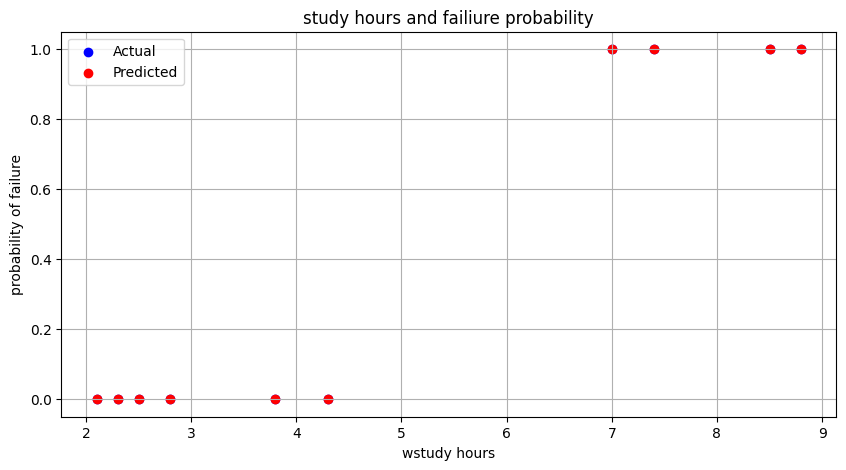

In [237]:
# plot to show study hours and fail
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.scatter(X_test, y_test, color='blue', label='Actual')
plt.scatter(X_test, y_pred, color='red', label='Predicted') 
plt.title('study hours and failiure probability')
plt.xlabel('wstudy hours')
plt.ylabel('probability of failure')
plt.legend()
plt.grid(True)
plt.show()


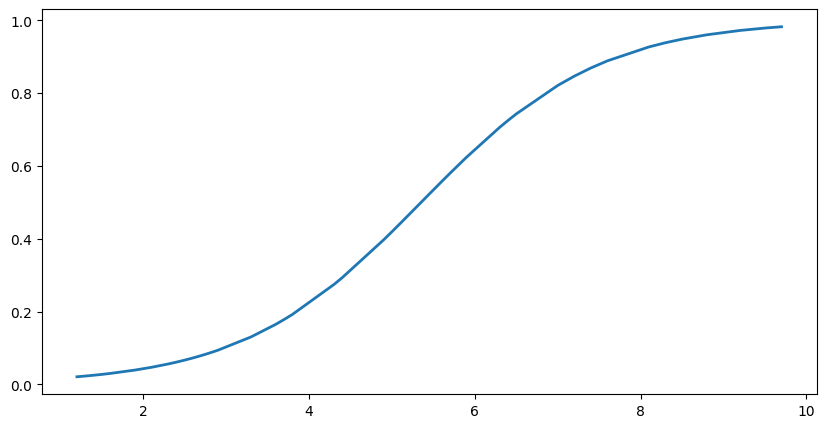

In [238]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5)) 
plt.plot(
    df["Study_Hours"],
    model.predict_proba(df[["Study_Hours"]])[:, 1],
    linewidth=2,
    label="Logistic Regression curve"
)
plt.show()